# 05 Cumulative returns in the test period (Figures 5 and 6)

In [1]:
import json
from dataclasses import fields
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from crash_prem_dual_model import DualModelConfig, compute_ibkr_cost_return, drift_weights, long_short_returns

MODEL_DIR = Path("ablation_outputs/A0_full/model")
STOCKS_DIR = Path("stocks_dir")

saved_cfg = json.loads((MODEL_DIR / "config.json").read_text())
cfg = DualModelConfig(**{k: v for k, v in saved_cfg.items() if k in {f.name for f in fields(DualModelConfig)}})

pred = pd.read_parquet(MODEL_DIR / "predictions.parquet")
strategy = pd.read_parquet(MODEL_DIR / "confidence_weighted_strategy.parquet")
pred = pred[pred["split"] == "test"].copy()
strategy = strategy[strategy["split"] == "test"].copy()
for df in (pred, strategy):
    df["date"] = pd.to_datetime(df["date"]).dt.normalize()
pred = pred.sort_values(["date", "ticker"])
strategy = strategy.sort_values(["date", "ticker"])

## Figure 6: contribution of each stock

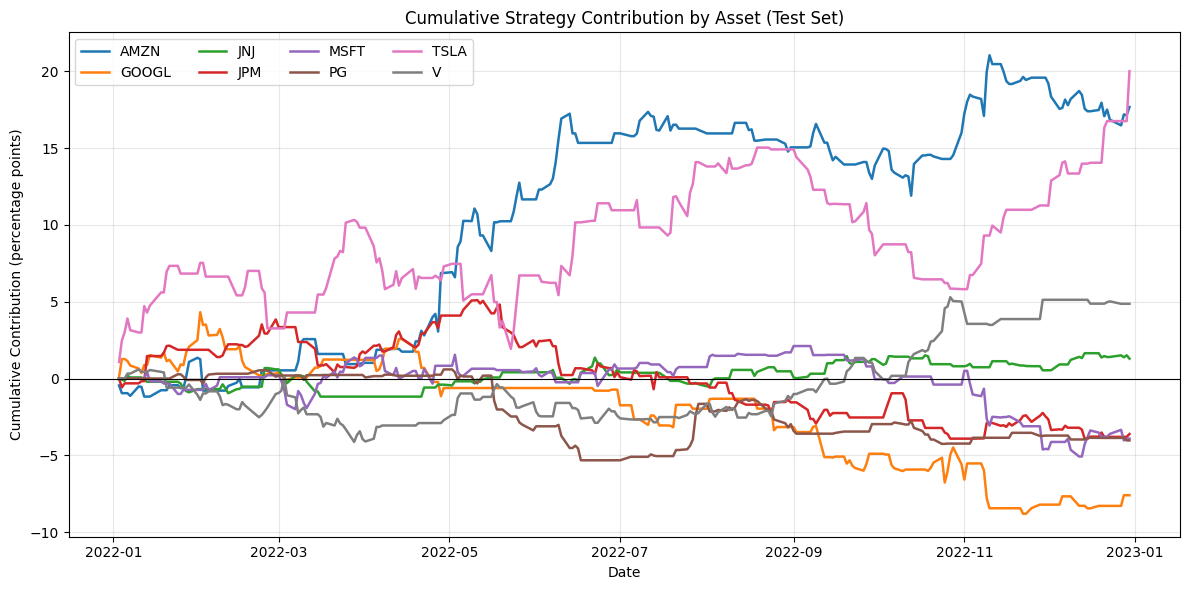

ticker
AMZN     17.67
GOOGL    -7.60
JNJ       1.29
JPM      -3.61
MSFT     -3.91
PG       -4.03
TSLA     20.01
V         4.86


In [2]:
contrib_cum = strategy.pivot_table(
    index="date", columns="ticker", values="position_return", aggfunc="sum"
).sort_index().fillna(0).cumsum() * 100

plt.figure(figsize=(12, 6))
for ticker in contrib_cum.columns:
    plt.plot(contrib_cum.index, contrib_cum[ticker], label=ticker, linewidth=1.8)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Cumulative Strategy Contribution by Asset (Test Set)")
plt.xlabel("Date")
plt.ylabel("Cumulative Contribution (percentage points)")
plt.legend(ncol=4)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cumulative_asset_contributions_test.png", dpi=300, bbox_inches="tight")
plt.show()

print(contrib_cum.iloc[-1].round(2).to_string())

## Figure 5: CWS against buy-and-hold and 20-day momentum

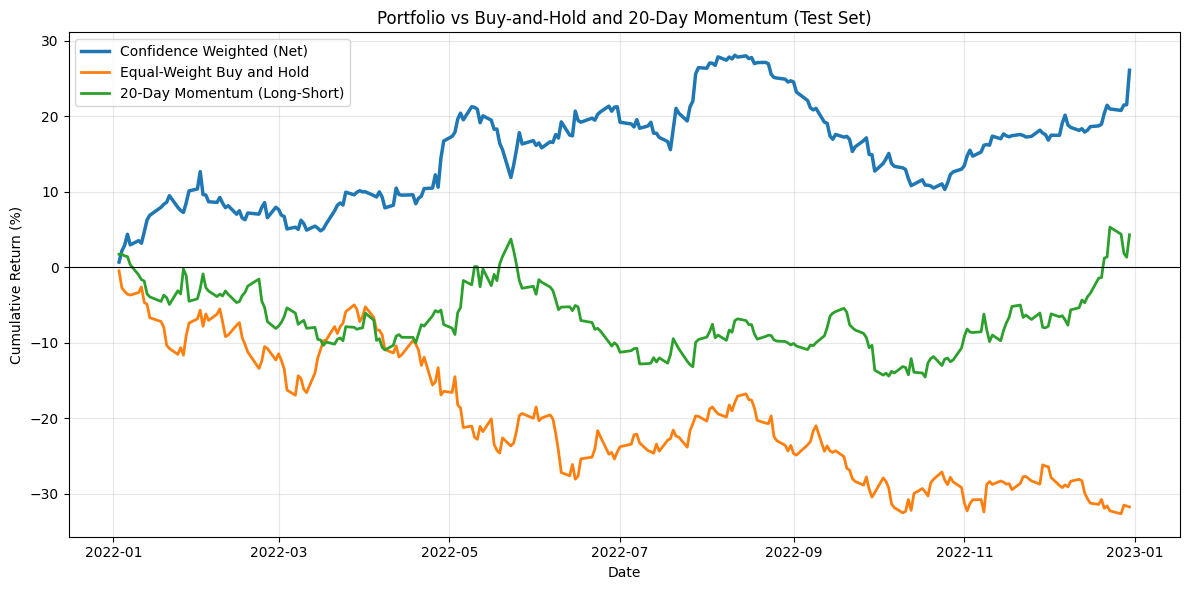

Confidence Weighted (Net)    26.08
Buy and Hold (Net)          -31.78
20-Day Momentum L/S (Net)     4.29


In [ ]:
def load_stock_prices(tickers):
    """Split-adjusted close for returns and momentum, contract-basis spot for share counts."""
    close, trade = {}, {}
    for ticker in tickers:
        s = pd.read_csv(STOCKS_DIR / f"{ticker}_stock.csv")
        s["date"] = pd.to_datetime(s["date"]).dt.normalize()
        s = s[(s["close_yahoo_split_adjusted"] > 0) & (s["spot"] > 0)].sort_values("date")
        s = s.drop_duplicates("date", keep="last").set_index("date")
        close[ticker] = s["close_yahoo_split_adjusted"].rename(ticker)
        trade[ticker] = s["spot"].rename(ticker)
    return pd.concat(close.values(), axis=1).sort_index(), pd.concat(trade.values(), axis=1).sort_index()


def to_long(wide, name):
    return wide.rename_axis(index="date", columns="ticker").reset_index().melt(
        id_vars="date", var_name="ticker", value_name=name)


def momentum_returns(dates, close, trade):
    """EWLS portfolio ranked by 20-day momentum, built with the strategy's long-short function."""
    panel = (to_long(close.shift(1) / close.shift(21) - 1, "prediction")
             .merge(to_long(np.log(close.shift(-1) / close), "target"), on=["date", "ticker"])
             .merge(to_long(trade, "close"), on=["date", "ticker"]))
    panel = panel[panel["date"].isin(dates)].dropna()
    daily = long_short_returns(panel, cfg.top_k, cfg).set_index("date")["net"]
    return daily.reindex(dates).fillna(0.0)


def buy_and_hold_returns(dates, close, trade):
    """Equal weights bought on the first day and left to drift; commission only on the initial purchase."""
    log_ret = np.log(close.shift(-1) / close)
    tickers = list(close.columns)
    w = {t: cfg.gross_exposure / len(tickers) for t in tickers}
    _, entry_cost = compute_ibkr_cost_return({}, w, trade.loc[dates[0]].to_dict(), cfg)
    out = []
    for i, date in enumerate(dates):
        r = log_ret.loc[date].fillna(0.0).to_dict()
        out.append(sum(w[t] * r[t] for t in tickers) - (entry_cost if i == 0 else 0.0))
        w = drift_weights(w, r, cfg.target_is_log_return)
    return pd.Series(out, index=dates)


portfolio_daily = strategy.groupby("date")[["strategy_return", "strategy_return_gross"]].first().sort_index()
dates = portfolio_daily.index
tickers = sorted(pred["ticker"].unique())
close, trade = load_stock_prices(tickers)

comparison = pd.DataFrame({
    "Confidence Weighted (Net)": portfolio_daily["strategy_return"],
    "Buy and Hold (Net)": buy_and_hold_returns(dates, close, trade),
    "20-Day Momentum L/S (Net)": momentum_returns(dates, close, trade),
})
portfolio_cum = ((1 + comparison).cumprod() - 1) * 100

plt.figure(figsize=(12, 6))
plt.plot(portfolio_cum.index, portfolio_cum["Confidence Weighted (Net)"],
         label="Confidence Weighted (Net)", linewidth=2.5)

plt.plot(portfolio_cum.index, portfolio_cum["Buy and Hold (Net)"],
         label="Equal-Weight Buy and Hold", linewidth=2)
plt.plot(portfolio_cum.index, portfolio_cum["20-Day Momentum L/S (Net)"],
         label="20-Day Momentum (Long-Short)", linewidth=2)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Portfolio vs Buy-and-Hold and 20-Day Momentum (Test Set)")
plt.xlabel("Date")
plt.ylabel("Cumulative Return (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cumulative_portfolio_return_test.png", dpi=300, bbox_inches="tight")
plt.show()

print(portfolio_cum.iloc[-1].round(2).to_string())